# Práctica EDA — Iris (con solución)

**Dataset:** Iris · Python / Pandas / NumPy / Matplotlib / Seaborn

El dataset **Iris** es uno de los más famosos de la historia del análisis de datos (Ronald Fisher, 1936). Contiene **150 flores** de 3 especies del género *Iris* y, para cada una, 4 medidas en centímetros de sus **sépalos** (las hojas verdes externas) y **pétalos** (las hojas de color internas).

La pregunta que guía este EDA es: **¿podemos distinguir la especie de una flor usando solo sus medidas?**

- CSV directo: https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv

| Columna | Descripción |
|---|---|
| `sepal_length` | Largo del sépalo (cm) |
| `sepal_width` | Ancho del sépalo (cm) |
| `petal_length` | Largo del pétalo (cm) |
| `petal_width` | Ancho del pétalo (cm) |
| `species` | Especie: setosa, versicolor o virginica |

**Instrucciones**
- Ejecuta las celdas en orden: muchas dependen de resultados anteriores.
- Cada pregunta tiene su enunciado y debajo la **solución**. Intenta resolverla primero por tu cuenta.
- Las celdas **Interpretación** explican la conclusión de cada análisis.

---
## Configuración

Importamos las librerías, definimos el estilo y asignamos **un color fijo por especie** para que cada una se vea igual en todos los gráficos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

orden_especies = ["setosa", "versicolor", "virginica"]
colores_especie = {"setosa": "#2a78d6", "versicolor": "#eb6834", "virginica": "#1baf7a"}

columnas_numericas = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

---
## PARTE 1 — Inspección y calidad de datos

### 1. Carga del dataset

Carga el CSV en un DataFrame llamado `df`, muestra las primeras 5 filas e indica cuántas filas y columnas tiene.

In [2]:
# Solución
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
df = pd.read_csv(url)

print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")
df.head()

Filas: 150 | Columnas: 5


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### 2. Tipos de datos y resumen estadístico

Usa `info()` para revisar los tipos de datos y `describe()` (redondeado a 2 decimales) para obtener las estadísticas de las columnas numéricas.

In [3]:
# Solución
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.2 KB


In [4]:
df.describe().round(2)

,sepal_length,sepal_width,petal_length,petal_width
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


💡 **Interpretación**
- Las 4 medidas son `float64` y `species` es texto. Las 150 filas tienen todas sus columnas completas.
- Los **pétalos varían mucho más** que los sépalos: `petal_length` va de 1.0 a 6.9 cm (desviación 1.77), mientras que `sepal_width` va de 2.0 a 4.4 cm (desviación 0.44).
- En `petal_length` la media (3.76) está **muy lejos** de la mediana (4.35). Eso sugiere que la distribución no es simétrica: probablemente hay grupos distintos mezclados.

### 3. Nulos y duplicados

1. Cuenta los valores nulos por columna.
2. Cuenta los registros duplicados y muestra **ambas** copias de las filas repetidas (pista: `duplicated(keep=False)`).

In [5]:
# Solución
df.isna().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

In [6]:
print(f"Registros duplicados: {df.duplicated().sum()}")

df[df.duplicated(keep=False)]

Registros duplicados: 1


,sepal_length,sepal_width,petal_length,petal_width,species
101,5.8,2.7,5.1,1.9,virginica
142,5.8,2.7,5.1,1.9,virginica


💡 **Interpretación**
- No hay valores nulos.
- Hay **1 fila duplicada** (índices 101 y 142): dos flores virginica con exactamente las mismas medidas.
- ¿Se elimina? El dataset **no tiene un ID** por flor y las medidas están redondeadas a 1 decimal, así que es perfectamente posible que sean **dos flores reales** con las mismas medidas. Por eso **la conservamos**. Eliminar duplicados solo tiene sentido cuando hay evidencia de que el registro se cargó dos veces (por ejemplo, el mismo ID repetido).

### 4. ¿Cuántas flores hay de cada especie?

Cuenta las flores por especie y grafícalas con `plt.bar`, usando el color de cada especie y mostrando el valor sobre cada barra.

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


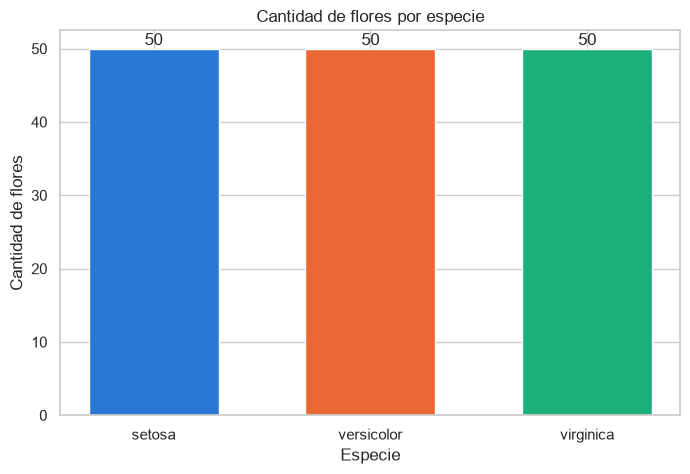

In [7]:
# Solución
conteo_especies = df["species"].value_counts().reindex(orden_especies)
print(conteo_especies)

colores = [colores_especie[especie] for especie in conteo_especies.index]
barras = plt.bar(conteo_especies.index, conteo_especies.values, color=colores, width=0.6)
plt.bar_label(barras)
plt.xlabel("Especie")
plt.ylabel("Cantidad de flores")
plt.title("Cantidad de flores por especie")
plt.show()

💡 **Interpretación**
- El dataset está **perfectamente balanceado**: 50 flores por especie. Ninguna especie pesa más que otra en los promedios generales, así que las comparaciones entre especies son justas.

---
## PARTE 2 — Análisis univariado

### 5. Distribución de las variables numéricas

Crea una figura de 2×2 con `plt.subplots` y dibuja un `sns.histplot` (con `kde=True`) por cada variable numérica. ¿Alguna variable muestra más de un "pico"?

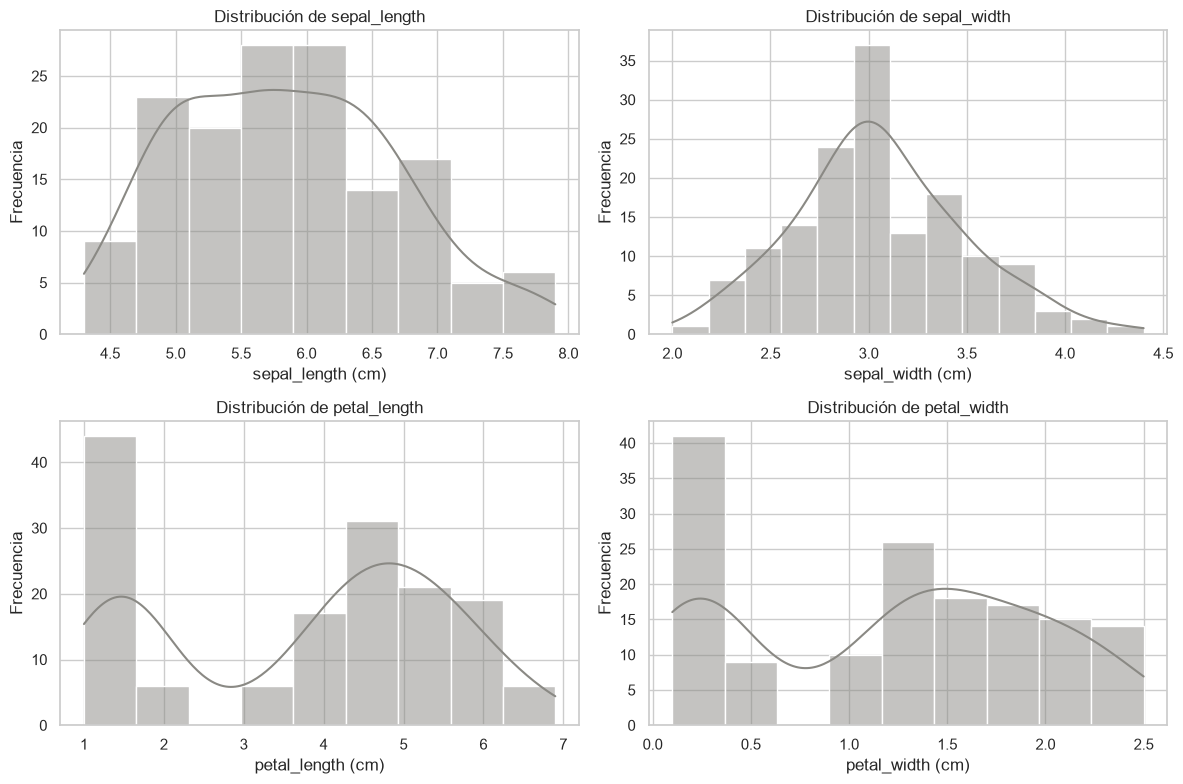

In [8]:
# Solución
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, columna in zip(axes.flat, columnas_numericas):
    sns.histplot(data=df, x=columna, kde=True, color="#8a8984", ax=ax)
    ax.set_title(f"Distribución de {columna}")
    ax.set_xlabel(f"{columna} (cm)")
    ax.set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

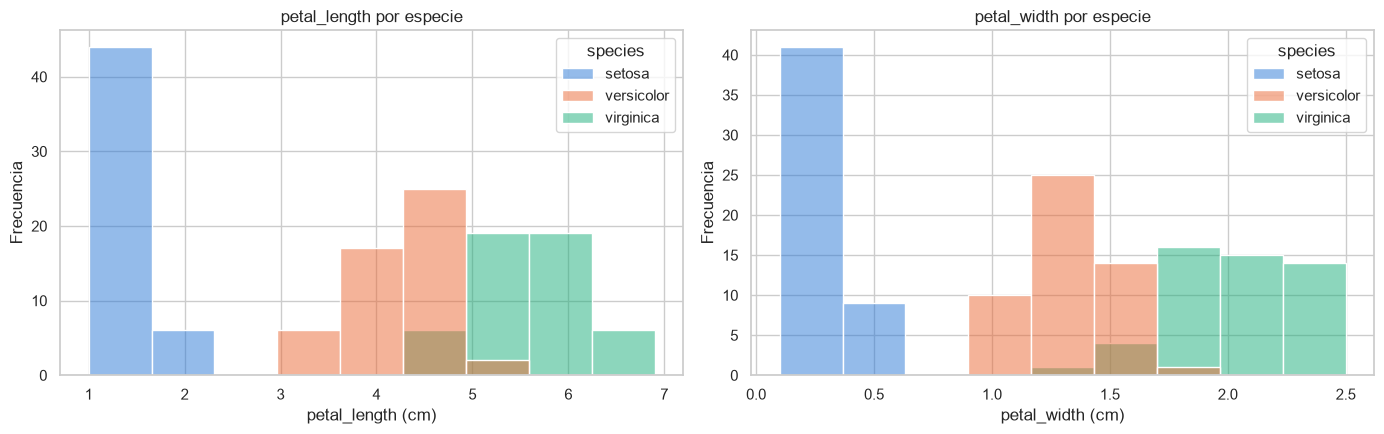

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for ax, columna in zip(axes, ["petal_length", "petal_width"]):
    sns.histplot(
        data=df, x=columna, hue="species",
        hue_order=orden_especies, palette=colores_especie, ax=ax
    )
    ax.set_title(f"{columna} por especie")
    ax.set_xlabel(f"{columna} (cm)")
    ax.set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

💡 **Interpretación**
- Los sépalos tienen distribuciones con **un solo pico**, parecidas a una campana.
- Los pétalos (`petal_length` y `petal_width`) muestran **dos grupos separados por un hueco**. Al colorear por especie, el grupo pequeño de la izquierda es **setosa**: sus pétalos son mucho más pequeños que los del resto.
- **Versicolor y virginica** forman el segundo grupo y se **solapan** un poco entre sí.

### 6. Boxplots por especie

Crea una figura de 1×4 con un `sns.boxplot` por variable, con la especie en el eje x. ¿Qué variable separa mejor a las especies? ¿Hay valores atípicos?

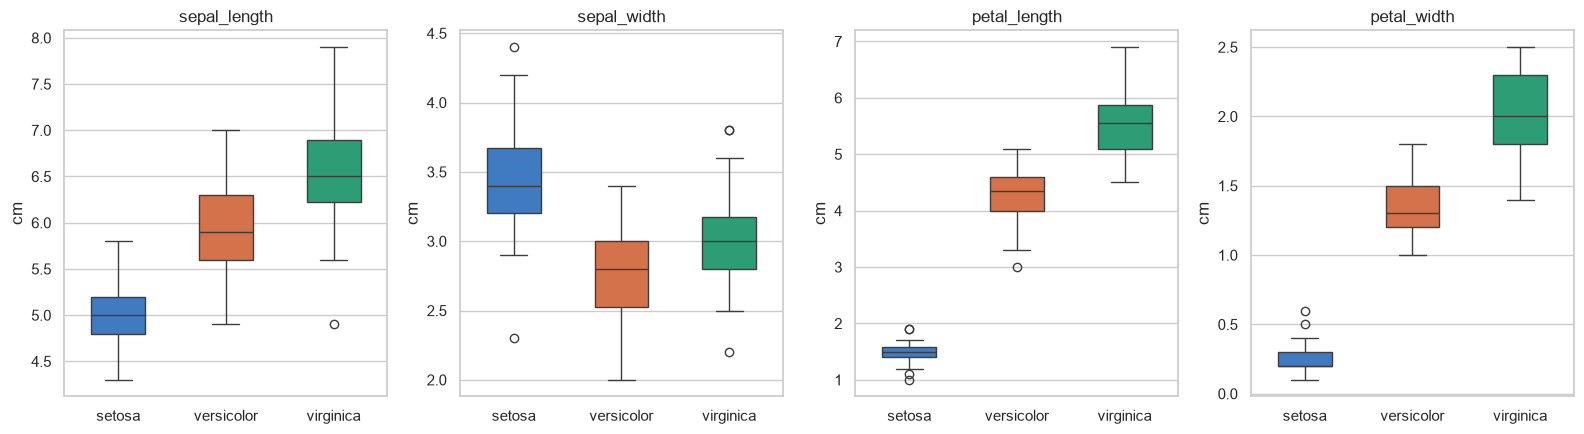

In [17]:
# Solución
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))

for ax, columna in zip(axes, columnas_numericas):
    sns.boxplot(
        data=df, x="species", y=columna, hue="species",
        order=orden_especies, palette=colores_especie, legend=False, width=0.5, ax=ax
    )
    ax.set_title(columna)
    ax.set_xlabel("")
    ax.set_ylabel("cm")

plt.tight_layout()
plt.show()

💡 **Interpretación**
- En `petal_length` y `petal_width` las cajas de las tres especies **no se tocan**: los pétalos son la mejor variable para separar especies.
- `sepal_width` es la peor: las cajas se solapan bastante. Además, es la única medida en la que **setosa tiene el valor más alto** (sépalos anchos y cortos).
- Aparecen algunos puntos atípicos (por ejemplo, en `sepal_width` de setosa), pero son pocos y tienen valores plausibles para una flor. No hay indicios de errores de medición.

---
## PARTE 3 — Comparación por especie

### 7. Perfil promedio de cada especie

1. Con `groupby` calcula el **promedio** de las 4 medidas por especie.
2. Visualiza esa tabla con `sns.heatmap` (`annot=True`).
3. Calcula el **mínimo y máximo** de `petal_length` por especie con `agg`. ¿Se solapan los rangos?

In [18]:
# Solución
promedios_especie = df.groupby("species")[columnas_numericas].mean().round(2)
promedios_especie

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


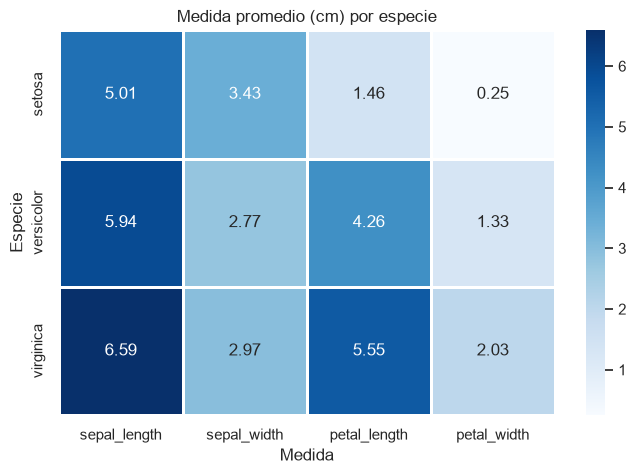

In [19]:
sns.heatmap(promedios_especie, annot=True, fmt=".2f", cmap="Blues", linewidths=2)
plt.title("Medida promedio (cm) por especie")
plt.xlabel("Medida")
plt.ylabel("Especie")
plt.show()

In [20]:
df.groupby("species")["petal_length"].agg(minimo="min", maximo="max", rango=lambda serie: serie.max() - serie.min())

,minimo,maximo,rango
species,,,
setosa,1.0,1.9,0.9
versicolor,3.0,5.1,2.1
virginica,4.5,6.9,2.4


💡 **Interpretación**
- Hay un patrón claro de tamaño: **setosa < versicolor < virginica** en largo de sépalo y en ambas medidas de pétalo.
- El pétalo de setosa mide como máximo **1.9 cm**, mientras que el de versicolor mide como mínimo **3.0 cm**: hay un hueco entre ambas especies.
- Versicolor (3.0–5.1 cm) y virginica (4.5–6.9 cm) **sí se solapan** entre 4.5 y 5.1 cm. Por eso esas dos especies son más difíciles de distinguir.

### 8. Nuevas variables: área del pétalo y forma del sépalo

1. Crea `petal_area` = `petal_length * petal_width` (una aproximación del tamaño del pétalo).
2. Crea `sepal_ratio` = `sepal_length / sepal_width` (valores altos = sépalo alargado).
3. Con `groupby` + `agg` calcula el promedio, mínimo y máximo de `petal_area` por especie.
4. Grafica `petal_area` por especie con `sns.boxplot` + `sns.stripplot`.

In [ ]:
# Solución
df["petal_area"] = df["petal_length"] * df["petal_width"]
df["sepal_ratio"] = (df["sepal_length"] / df["sepal_width"]).round(2)

df.groupby("species").agg(
    area_promedio=("petal_area", "mean"),
    area_minima=("petal_area", "min"),
    area_maxima=("petal_area", "max"),
    ratio_sepalo_promedio=("sepal_ratio", "mean")
).round(2)

In [ ]:
sns.boxplot(
    data=df, x="species", y="petal_area", hue="species",
    order=orden_especies, palette=colores_especie, legend=False, width=0.5, fliersize=0
)
sns.stripplot(
    data=df, x="species", y="petal_area",
    order=orden_especies, color="#0b0b0b", alpha=0.35, size=3
)
plt.title("Área aproximada del pétalo por especie")
plt.xlabel("Especie")
plt.ylabel("Área del pétalo (cm²)")
plt.show()

💡 **Interpretación**
- El área promedio del pétalo de virginica (≈11.3 cm²) es **el doble** que la de versicolor (≈5.7 cm²) y unas **30 veces** la de setosa (≈0.37 cm²).
- Combinar dos variables en una sola puede **separar mejor** los grupos. Con `petal_length`, versicolor y virginica comparten el rango de 4.5 a 5.1 cm, donde caen **37 flores**. Con `petal_area` comparten el rango de 7.5 a 8.64 cm², donde solo caen **10 flores**.
- `sepal_ratio` muestra que setosa tiene sépalos más "redondos" (≈1.5) y las otras dos más alargados (≈2.2).

---
## PARTE 4 — Relaciones entre variables

### 9. Matriz de correlación

Calcula la matriz de correlación de las 4 medidas originales y visualízala con `sns.heatmap`, usando una paleta divergente centrada en 0 (`cmap="RdBu_r"`, `vmin=-1`, `vmax=1`).

In [ ]:
# Solución
matriz_correlacion = df[columnas_numericas].corr()

sns.heatmap(
    matriz_correlacion, annot=True, fmt=".2f",
    cmap="RdBu_r", vmin=-1, vmax=1, center=0, linewidths=2, square=True
)
plt.title("Matriz de correlación")
plt.show()

💡 **Interpretación**
- **Largo y ancho del pétalo** tienen una correlación casi perfecta (**0.96**): una medida casi determina a la otra.
- El largo del sépalo también se relaciona fuertemente con los pétalos (0.87 y 0.82).
- `sepal_width` es la variable "rara": tiene correlación **negativa** con las demás y prácticamente **nula (−0.12)** con `sepal_length`. Por eso, como vimos en los boxplots, los sépalos ayudan poco a distinguir las especies.

### 10. Largo vs. ancho del pétalo

1. Haz un gráfico de dispersión básico con `plt.scatter` (`petal_length` en x, `petal_width` en y).
2. Repítelo con `sns.scatterplot` coloreando por especie.

In [ ]:
# Solución
plt.scatter(df["petal_length"], df["petal_width"], color="#8a8984", alpha=0.7)
plt.xlabel("Largo del pétalo (cm)")
plt.ylabel("Ancho del pétalo (cm)")
plt.title("Largo vs. ancho del pétalo")
plt.show()

In [ ]:
sns.scatterplot(
    data=df, x="petal_length", y="petal_width",
    hue="species", hue_order=orden_especies, palette=colores_especie, s=50, alpha=0.8
)
plt.xlabel("Largo del pétalo (cm)")
plt.ylabel("Ancho del pétalo (cm)")
plt.title("Largo vs. ancho del pétalo por especie")
plt.legend(title="Especie")
plt.show()

💡 **Interpretación**
- Los puntos forman una línea casi recta (correlación 0.96).
- Con color se ven **tres grupos**: setosa completamente aislada abajo a la izquierda, y versicolor y virginica una a continuación de la otra, con una pequeña zona de contacto alrededor de 5 cm de largo y 1.7 cm de ancho.
- Con solo estas dos medidas ya se puede clasificar casi cualquier flor. Lo comprobaremos en la pregunta 13.

### 11. Pairplot

Usa `sns.pairplot` con las 4 medidas originales, coloreando por especie (`corner=True`). ¿Qué par de variables separa mejor las tres especies?

In [ ]:
# Solución
sns.pairplot(
    df, vars=columnas_numericas,
    hue="species", hue_order=orden_especies, palette=colores_especie,
    corner=True, plot_kws={"alpha": 0.6, "s": 25}
)
plt.show()

💡 **Interpretación**
- **Setosa se separa de las otras especies en todos los gráficos** que incluyen alguna medida del pétalo.
- El par que mejor separa las tres especies es **`petal_length` vs. `petal_width`**. Los gráficos que solo usan sépalos (`sepal_length` vs. `sepal_width`) mezclan bastante versicolor y virginica.

---
## PARTE 5 — Integrador

### 12. Categorizar el largo del pétalo

1. Crea `petal_size` con `pd.cut()` sobre `petal_length`: **Corto** (≤ 2.5 cm), **Mediano** (2.5–5 cm) y **Largo** (> 5 cm).
2. Construye una tabla cruzada `species` × `petal_size` y visualízala con `sns.heatmap`.

In [ ]:
# Solución
df["petal_size"] = pd.cut(
    df["petal_length"],
    bins=[0, 2.5, 5, np.inf],
    labels=["Corto", "Mediano", "Largo"]
)

tabla_tamano = pd.crosstab(df["species"], df["petal_size"])
tabla_tamano

In [ ]:
sns.heatmap(tabla_tamano, annot=True, fmt="d", cmap="Blues", linewidths=2)
plt.title("Especie vs. tamaño del pétalo")
plt.xlabel("Tamaño del pétalo")
plt.ylabel("Especie")
plt.show()

💡 **Interpretación**
- **Las 50 setosas** tienen pétalo corto y **ninguna otra especie** lo tiene: la categoría "Corto" identifica a setosa sin errores.
- 49 de 50 versicolor tienen pétalo mediano y 41 de 50 virginica pétalo largo. Las **9 virginica con pétalo mediano** son la zona de solapamiento que vimos en las preguntas 7 y 10.

### 13. Clasificador con reglas simples

Con lo aprendido en el EDA, crea una columna `prediccion` usando `np.where` anidado con estas reglas:
- Si `petal_length < 2.5` → `"setosa"`
- Si no, si `petal_width < 1.75` → `"versicolor"`
- En otro caso → `"virginica"`

Luego calcula el **porcentaje de aciertos** (cuántas veces `prediccion == species`) y construye una tabla cruzada `species` × `prediccion` para ver los errores.

In [ ]:
# Solución
df["prediccion"] = np.where(
    df["petal_length"] < 2.5,
    "setosa",
    np.where(df["petal_width"] < 1.75, "versicolor", "virginica")
)

aciertos = (df["prediccion"] == df["species"]).mean() * 100
print(f"Porcentaje de aciertos: {aciertos:.1f}%")

pd.crosstab(df["species"], df["prediccion"])

In [ ]:
# ¿Qué flores se clasificaron mal?
errores = df[df["prediccion"] != df["species"]]
errores[["species", "prediccion"] + columnas_numericas]

💡 **Interpretación**
- Con **solo dos reglas** basadas en los pétalos clasificamos correctamente el **96%** de las flores.
- Setosa se acierta el 100% de las veces. Los 6 errores están entre **versicolor y virginica**, justo en la zona de solapamiento.
- Esta es la idea detrás de un **árbol de decisión**, uno de los modelos de machine learning más usados. Un buen EDA no solo describe los datos: también **sugiere qué variables usar** y cómo.

### 14. Dashboard y reporte final

1. Construye una figura de 2×2 con `plt.subplots` que resuma el EDA:
   - Largo del pétalo por especie (`sns.boxplot`).
   - Largo vs. ancho del pétalo por especie (`sns.scatterplot`).
   - Matriz de correlación (`sns.heatmap`).
   - Promedio de cada medida por especie (`sns.barplot`).
2. Guarda la figura en `../data/iris_dashboard.png`.
3. Crea `iris_report` con una fila por especie: cantidad de flores, promedio de cada medida y `petal_area` promedio (redondeado a 2 decimales). Expórtalo a `../data/iris_report.csv` sin índice.

In [ ]:
# Solución
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Largo del pétalo por especie
ax = axes[0, 0]
sns.boxplot(
    data=df, x="species", y="petal_length", hue="species",
    order=orden_especies, palette=colores_especie, legend=False, width=0.5, ax=ax
)
ax.set_title("1. Largo del pétalo por especie")
ax.set_xlabel("Especie")
ax.set_ylabel("Largo del pétalo (cm)")

# 2. Largo vs. ancho del pétalo
ax = axes[0, 1]
sns.scatterplot(
    data=df, x="petal_length", y="petal_width",
    hue="species", hue_order=orden_especies, palette=colores_especie, alpha=0.8, ax=ax
)
ax.set_title("2. Largo vs. ancho del pétalo")
ax.set_xlabel("Largo del pétalo (cm)")
ax.set_ylabel("Ancho del pétalo (cm)")
ax.legend(title="Especie")

# 3. Matriz de correlación
ax = axes[1, 0]
sns.heatmap(
    matriz_correlacion, annot=True, fmt=".2f",
    cmap="RdBu_r", vmin=-1, vmax=1, center=0, linewidths=2, ax=ax
)
ax.set_title("3. Matriz de correlación")

# 4. Promedio de cada medida por especie
ax = axes[1, 1]
promedios_largo = promedios_especie.reset_index().melt(
    id_vars="species", var_name="medida", value_name="cm"
)
sns.barplot(
    data=promedios_largo, x="medida", y="cm", hue="species",
    hue_order=orden_especies, palette=colores_especie, ax=ax
)
ax.set_title("4. Medida promedio por especie")
ax.set_xlabel("")
ax.set_ylabel("Promedio (cm)")
ax.legend(title="Especie")

fig.suptitle("EDA Iris — Resumen", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig("../data/iris_dashboard.png", dpi=150, bbox_inches="tight")
plt.show()

> **Nota:** en el gráfico 4 usamos `melt()`, que convierte la tabla de promedios de formato "ancho" (una columna por medida) a formato "largo" (una fila por especie y medida). Seaborn necesita el formato largo para dibujar varias medidas con `hue`.

In [ ]:
import pandas as pd

df_ejemplo = pd.DataFrame({
    "Alumno": ["Ana", "Luis"],
    "Matemática": [18, 15],
    "Historia": [16, 17]
})

print("Tabla original:")
print(df_ejemplo)

df_largo = df_ejemplo.melt(
    id_vars="Alumno",
    var_name="Curso",
    value_name="Nota"
)

print("\nTabla después de melt:")
print(df_largo)

In [ ]:
iris_report = df.groupby("species").agg(
    total_flores=("species", "count"),
    avg_sepal_length=("sepal_length", "mean"),
    avg_sepal_width=("sepal_width", "mean"),
    avg_petal_length=("petal_length", "mean"),
    avg_petal_width=("petal_width", "mean"),
    avg_petal_area=("petal_area", "mean")
).round(2).reset_index()

iris_report.to_csv("../data/iris_report.csv", index=False)
iris_report

---
## Conclusiones del EDA

1. **Datos limpios:** 150 flores, sin nulos y con 1 fila duplicada que se conserva porque puede corresponder a dos flores reales.
2. **Clases balanceadas:** 50 flores por especie, así que las comparaciones entre especies son justas.
3. **Los pétalos son la clave:** separan muy bien a las especies, mientras que los sépalos (sobre todo `sepal_width`) se solapan mucho.
4. **Setosa es inconfundible:** pétalo de 1.9 cm como máximo, frente a 3.0 cm o más en las otras especies.
5. **Versicolor y virginica se solapan** en pétalos de 4.5 a 5.1 cm de largo: es la única zona difícil de clasificar.
6. **Respuesta a la pregunta inicial:** sí, la especie se puede distinguir con las medidas. Dos reglas sobre el pétalo aciertan el **96%** de las veces.